# Grouping Chess games based on game information
## Question
Is it possible to group Chess games based on different game statistics, like move count, player ratings, opening moves played, etc. This notebook attempts to group games using the kmeans clustering algorithm.

The target is to plot the clusters and visually see distinct groups.


In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [80]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)
data.head(1)

,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
id,,,,,,,,,,,,,,,
TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5


## Selecting our features
First we have to select our baseline features we'd like to group. We will begin with just both player ratings, opening plies, and the turn count.

In [81]:
features = ['white_rating', 'black_rating', 'opening_ply', 'turns']

X = data[features].dropna()
print(X.head())

          white_rating  black_rating  opening_ply  turns
id                                                      
TZJHLljE          1500          1191            5     13
l1NXvwaE          1322          1261            4     16
mIICvQHh          1496          1500            3     61
kWKvrqYL          1439          1454            3     61
9tXo1AUZ          1523          1469            5     95


In [ ]:
def number_of_checks(moves):
    moves = moves.split()
    return sum(1 for move in moves if '+' in move)

def number_of_captures(moves, colour):
    moves = moves.split()
    if (colour == 'white'):
        return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 0)
    return sum(1 for i, move in enumerate(moves) if 'x' in move and i % 2 == 1)

def number_of_castles(moves):
    moves = moves.split()
    return sum(1 for move in moves if 'O-O' in move or 'O-O-O' in move)



## Additional features
The basic features might not have enough variation to produce any clear groups. Since we have the move list for each game, we can quite simply calculate a lot of information about the game itself, e.g. number of captures, number of checks.

In [83]:
X['number_of_checks'] = data['moves'].apply(number_of_checks)
X['number_of_captures_white'] = data['moves'].apply(number_of_captures, colour='white')
X['number_of_captures_black'] = data['moves'].apply(number_of_captures, colour='black')
X['number_of_castles'] = data['moves'].apply(number_of_castles)

Some features, however, might skew the cluster values, so we can transform the features using a scaler.

In [84]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Training the model
Now that the data is ready, we can create our clustering model. 

In [85]:
CLUSTER_COUNT = 4
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=42)

clusters = kmeans.fit_predict(X_scaled)

X['cluster'] = clusters
cluster_summary = X.groupby("cluster")[X.columns].mean()

print(cluster_summary)

         white_rating  black_rating  opening_ply       turns  \
cluster                                                        
0         1605.967342   1610.825030     4.664839  108.763528   
1         1876.573293   1867.017023     6.552109   56.175903   
2         1474.756249   1454.212568     3.912402   23.283028   
3         1438.637647   1432.363137     4.074196   56.745098   

         number_of_checks  number_of_captures_white  number_of_captures_black  \
cluster                                                                         
0               11.296544                 12.133969                 12.057449   
1                2.888595                  6.684698                  6.700965   
2                1.503452                  2.636039                  2.544632   
3                4.137098                  7.391529                  7.336157   

         number_of_castles  cluster  
cluster                              
0                 1.542074      0.0  
1             

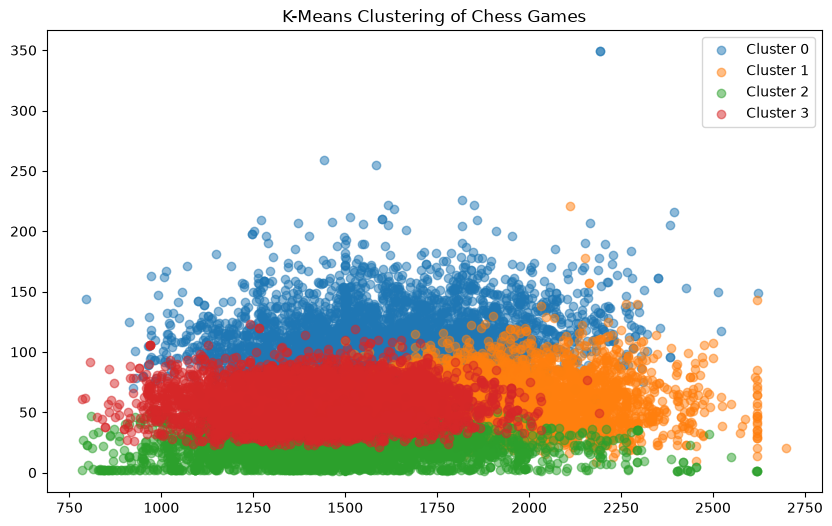

In [86]:
# Plot the clusters
plt.figure(figsize=(10, 6))
for cluster in range(CLUSTER_COUNT):
    cluster_data = X[X['cluster'] == cluster]
    plt.scatter(cluster_data['white_rating'], cluster_data['turns'], label=f'Cluster {cluster}', alpha=0.5)
plt.title('K-Means Clustering of Chess Games')
plt.legend()
plt.show()